# Get h5ad of different species

*Harpegnathos saltator*

In [ ]:
%%bash

ln -sf "/home/liuzhiyu/Projects/neo_caste/anno_cells/Sheng_SA_2020_Hsal/Hsal51.h5ad" "./matrix/Hsal51.h5ad"
# The 2021 Harpegnathos saltator dataset; obtained the RDS file by contacting the authors, and converted it to h5ad format.

*Apis mellifera*

In [ ]:
%%bash

wget -O "./matrix/GSE184507.tar" "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE184507"

In [ ]:
# merge the 2022 Apis mellifera dataset from GEO (GSE184507_RAW.tar) into a single h5ad file
import scanpy as sc
import anndata as ad
from pathlib import Path

raw_dir = Path("./matrix/GSE184507_RAW")
prefixes = sorted(p.name[: -len("matrix.mtx.gz")] for p in raw_dir.glob("*matrix.mtx.gz"))

adatas = [
    sc.read_10x_mtx(raw_dir, prefix=p, var_names="gene_symbols", gex_only=True)
    for p in prefixes
]

adata = ad.concat(
    adatas,
    join="outer",
    label="sample",
    keys=[p[:-1] for p in prefixes],
    index_unique="-",
)
adata.write_h5ad("./matrix/GSE184507.h5ad")
adata

In [ ]:
adata.obs
# 141,510 rows

,sample
AAACCCAAGAGCCTGA-1-GSM5590453_scFoager1,GSM5590453_scFoager1
AAACCCAAGAGTCACG-1-GSM5590453_scFoager1,GSM5590453_scFoager1
AAACCCAAGCACTCGC-1-GSM5590453_scFoager1,GSM5590453_scFoager1
AAACCCAAGCGCACAA-1-GSM5590453_scFoager1,GSM5590453_scFoager1
AAACCCAAGCGTCGAA-1-GSM5590453_scFoager1,GSM5590453_scFoager1
...,...
TTTGTTGTCGGCTTGG-1-GSM5590458_scQueen2,GSM5590458_scQueen2
TTTGTTGTCTACCCAC-1-GSM5590458_scQueen2,GSM5590458_scQueen2
TTTGTTGTCTCACTCG-1-GSM5590458_scQueen2,GSM5590458_scQueen2
TTTGTTGTCTCCTGAC-1-GSM5590458_scQueen2,GSM5590458_scQueen2


In [ ]:
%%bash
# adata does not contain annotations; these were obtained subsequently by contacting the original authors of iScience (2022).
ln -sf "/home/liuzhiyu/Projects/neo_caste/anno_cells/Zhang_iScience_2022_Amel/metadata/metadata.csv" "./metadata/metadata.csv"

In [20]:
import pandas as pd

Amel_anno = pd.read_csv("./metadata/metadata.csv")
Amel_anno # 115169 rows

/tmp/ipykernel_102804/649958447.py:3: DtypeWarning: Columns (5,7) have mixed types. Specify dtype option on import or set low_memory=False.
  Amel_anno = pd.read_csv("./metadata/metadata.csv")


,Unnamed: 0,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,f,n,q,integrated_snn_res.1,seurat_clusters,type,cell_type
0,F1_sc_AAACCCAAGAGCCTGA-1,F1,4938,2284,5.548805,F,NaN,NaN,24,24,F,UNs
1,F1_sc_AAACCCAAGAGTCACG-1,F1,2181,1277,7.473636,F,NaN,NaN,9,9,F,KCs
2,F1_sc_AAACCCAAGCACTCGC-1,F1,5417,2227,12.017722,F,NaN,NaN,6,6,F,OPNs
3,F1_sc_AAACCCAAGCGCACAA-1,F1,5231,2255,6.652648,F,NaN,NaN,25,25,F,Glial cells
4,F1_sc_AAACCCAAGGCCCGTT-1,F1,6388,2624,5.541641,F,NaN,NaN,34,34,F,KCs
...,...,...,...,...,...,...,...,...,...,...,...,...
115164,Q2_sc_TTTGTTGTCCGTGGCA-1,Q2,6349,2577,5.937943,NaN,NaN,Q,3,3,Q,UNs
115165,Q2_sc_TTTGTTGTCGGCTTGG-1,Q2,3377,1682,6.692330,NaN,NaN,Q,5,5,Q,KCs
115166,Q2_sc_TTTGTTGTCTACCCAC-1,Q2,1849,999,13.142239,NaN,NaN,Q,32,32,Q,Glial cells
115167,Q2_sc_TTTGTTGTCTCACTCG-1,Q2,5251,2194,4.532470,NaN,NaN,Q,11,11,Q,KCs


In [6]:
Amel_anno['Unnamed: 0'].unique()

array(['F1_sc_AAACCCAAGAGCCTGA-1', 'F1_sc_AAACCCAAGAGTCACG-1',
       'F1_sc_AAACCCAAGCACTCGC-1', ..., 'Q2_sc_TTTGTTGTCTACCCAC-1',
       'Q2_sc_TTTGTTGTCTCACTCG-1', 'Q2_sc_TTTGTTGTCTCTGGTC-1'],
      shape=(115169,), dtype=object)

In [22]:
# combine the annotations with the adata object
adata.obs.index

Index(['AAACCCAAGAGCCTGA-1-GSM5590453_scFoager1',
       'AAACCCAAGAGTCACG-1-GSM5590453_scFoager1',
       'AAACCCAAGCACTCGC-1-GSM5590453_scFoager1',
       'AAACCCAAGCGCACAA-1-GSM5590453_scFoager1',
       'AAACCCAAGCGTCGAA-1-GSM5590453_scFoager1',
       'AAACCCAAGGCCCGTT-1-GSM5590453_scFoager1',
       'AAACCCAAGGTCCGAA-1-GSM5590453_scFoager1',
       'AAACCCAAGTCTACCA-1-GSM5590453_scFoager1',
       'AAACCCAAGTTTGAGA-1-GSM5590453_scFoager1',
       'AAACCCACAAGAATGT-1-GSM5590453_scFoager1',
       ...
       'TTTGTTGGTTCAAGTC-1-GSM5590458_scQueen2',
       'TTTGTTGGTTGTTTGG-1-GSM5590458_scQueen2',
       'TTTGTTGTCCAGGACC-1-GSM5590458_scQueen2',
       'TTTGTTGTCCATGCAA-1-GSM5590458_scQueen2',
       'TTTGTTGTCCGTGGCA-1-GSM5590458_scQueen2',
       'TTTGTTGTCGGCTTGG-1-GSM5590458_scQueen2',
       'TTTGTTGTCTACCCAC-1-GSM5590458_scQueen2',
       'TTTGTTGTCTCACTCG-1-GSM5590458_scQueen2',
       'TTTGTTGTCTCCTGAC-1-GSM5590458_scQueen2',
       'TTTGTTGTCTCTGGTC-1-GSM5590458_scQueen2']

In [23]:
sample_map = {
    "GSM5590453_scFoager1": "F1", "GSM5590454_scFoager2": "F2",
    "GSM5590455_scNurse1":  "N1", "GSM5590456_scNurse2":  "N2",
    "GSM5590457_scQueen1":  "Q1", "GSM5590458_scQueen2":  "Q2",
}

barcode = adata.obs_names.str.rsplit("-", n=1).str[0] # AAACCCAAGAGCCTGA-1
code = adata.obs["sample"].astype(str).map(sample_map) # GSM...scFoager1 -> F1
adata.obs["amel_key"] = code + "_sc_" + barcode # F1_sc_AAACCCAAGAGCCTGA-1

adata.obs = adata.obs.join(Amel_anno.set_index("Unnamed: 0"), on="amel_key")

In [24]:
adata.obs[~adata.obs["orig.ident"].isna()]
# After removing NAs, 115,169 rows in total, matching Amel_anno;

,sample,amel_key,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,f,n,q,integrated_snn_res.1,seurat_clusters,type,cell_type
AAACCCAAGAGCCTGA-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGAGCCTGA-1,F1,4938.0,2284.0,5.548805,F,NaN,NaN,24.0,24.0,F,UNs
AAACCCAAGAGTCACG-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGAGTCACG-1,F1,2181.0,1277.0,7.473636,F,NaN,NaN,9.0,9.0,F,KCs
AAACCCAAGCACTCGC-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGCACTCGC-1,F1,5417.0,2227.0,12.017722,F,NaN,NaN,6.0,6.0,F,OPNs
AAACCCAAGCGCACAA-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGCGCACAA-1,F1,5231.0,2255.0,6.652648,F,NaN,NaN,25.0,25.0,F,Glial cells
AAACCCAAGGCCCGTT-1-GSM5590453_scFoager1,GSM5590453_scFoager1,F1_sc_AAACCCAAGGCCCGTT-1,F1,6388.0,2624.0,5.541641,F,NaN,NaN,34.0,34.0,F,KCs
...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTTGTCCGTGGCA-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCCGTGGCA-1,Q2,6349.0,2577.0,5.937943,NaN,NaN,Q,3.0,3.0,Q,UNs
TTTGTTGTCGGCTTGG-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCGGCTTGG-1,Q2,3377.0,1682.0,6.692330,NaN,NaN,Q,5.0,5.0,Q,KCs
TTTGTTGTCTACCCAC-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCTACCCAC-1,Q2,1849.0,999.0,13.142239,NaN,NaN,Q,32.0,32.0,Q,Glial cells
TTTGTTGTCTCACTCG-1-GSM5590458_scQueen2,GSM5590458_scQueen2,Q2_sc_TTTGTTGTCTCACTCG-1,Q2,5251.0,2194.0,4.532470,NaN,NaN,Q,11.0,11.0,Q,KCs


In [25]:
# In the original 2022 iScience article, the authors incorrectly labeled the mitochondrial genes; the "MT-" prefix has been removed in all instances here.
adata.var_names = adata.var_names.str.replace("^MT-", "", regex=True)
adata.var_names_make_unique()
adata.write_h5ad("./matrix/Amel_wll.h5ad")

*Drosophila melanogaster*

In [22]:
%%bash

wget -O "./matrix/Dmel.loom" "https://flybrain.aertslab.org/downloads/loom/Davie_Janssens_Koldere_et_al_2018_AdultBrain.loom"

--2026-10-08 23:11:22--  https://flybrain.aertslab.org/downloads/loom/Davie_Janssens_Koldere_et_al_2018_AdultBrain.loom


Resolving flybrain.aertslab.org (flybrain.aertslab.org)... 134.58.50.9
Connecting to flybrain.aertslab.org (flybrain.aertslab.org)|134.58.50.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 519015198 (495M)
Saving to: './matrix/Dmel.loom'

     0K .......... .......... .......... .......... ..........  0%  169K 50m3s
    50K .......... .......... .......... .......... ..........  0%  338K 37m32s
   100K .......... .......... .......... .......... ..........  0%  340K 33m18s
   150K .......... .......... .......... .......... ..........  0% 29.4M 25m2s
   200K .......... .......... .......... .......... ..........  0% 30.6M 20m5s
   250K .......... .......... .......... .......... ..........  0%  348K 20m47s
   300K .......... .......... .......... .......... ..........  0% 22.7M 17m52s
   350K .......... .......... .......... .......... ..........  0% 34.3M 15m40s
   400K .......... .......... .......... .......... ..........  0% 29.0M 13m57s
   450K ........

In [ ]:
import loompy
import anndata as ad
import pandas as pd

with loompy.connect("./matrix/Dmel.loom", validate=False) as ds:
    X = ds.layers[""].sparse().T.tocsr()                # cells × genes
    obs = pd.DataFrame(index=pd.Index(ds.ca["CellID"], name="CellID"))
    for k in ["ClusterID", "batch", "cell_type", "leiden",
              "n_counts", "n_genes", "percent_mito", "sample_id"]:
        obs[k] = ds.ca[k]
    var = pd.DataFrame(index=pd.Index(ds.ra["Gene"], name="Gene"))

Dmel = ad.AnnData(X=X, obs=obs, var=var)
Dmel

In [32]:
Dmel = ad.AnnData(X=X, obs=obs, var=var)
Dmel.write_h5ad("./matrix/Dmel.h5ad")

*Apis cerana*

In [33]:
%%bash

ln -sf "/home/liuzhiyu/Projects/neo_caste/anno_cells/Acer/matrix/01_Acer_transfromHY.h5ad" "./matrix/01_Acer_transfromHY.h5ad"

# Get Orthologs

In [ ]:
%%bash

cp "/home/liuzhiyu/Projects/neo_caste/Find_Ortholog/primary_transcripts/OrthoFinder/Results_Sep13/Orthologues/Orthologues_Apis_cerana/Apis_cerana__v__Apis_mellifera.tsv" "./orthologs/Apis_cerana__v__Apis_mellifera.tsv"
cp "/home/liuzhiyu/Projects/neo_caste/Find_Ortholog/primary_transcripts/OrthoFinder/Results_Sep13/Orthologues/Orthologues_Apis_cerana/Apis_cerana__v__Drosophila_melanogaster.tsv" "./orthologs/Apis_cerana__v__Drosophila_melanogaster.tsv"
cp "/home/liuzhiyu/Projects/neo_caste/Find_Ortholog/primary_transcripts/OrthoFinder/Results_Sep13/Orthologues/Orthologues_Apis_cerana/Apis_cerana__v__Harpegnathos_saltator.tsv" "./orthologs/Apis_cerana__v__Harpegnathos_saltator.tsv"

In [2]:
import pandas as pd

Acer_vs_Amel = pd.read_csv("./orthologs/Apis_cerana__v__Apis_mellifera.tsv", sep="\t")
Acer_vs_Dmel = pd.read_csv("./orthologs/Apis_cerana__v__Drosophila_melanogaster.tsv", sep="\t")
Acer_vs_Hsal = pd.read_csv("./orthologs/Apis_cerana__v__Harpegnathos_saltator.tsv", sep="\t")

In [7]:
def get_121_orthologs(df, sp1, sp2):
    df_121 = df[
        ~df[sp1].str.contains(",", na=False)
        & ~df[sp2].str.contains(",", na=False)
    ]
    return df_121

In [8]:
Acer_vs_Amel_121 = get_121_orthologs(Acer_vs_Amel, "Apis_cerana", "Apis_mellifera")
Acer_vs_Dmel_121 = get_121_orthologs(Acer_vs_Dmel, "Apis_cerana", "Drosophila_melanogaster")
Acer_vs_Hsal_121 = get_121_orthologs(Acer_vs_Hsal, "Apis_cerana", "Harpegnathos_saltator")

In [14]:
Acer_vs_Amel_121.to_csv("./orthologs/Acer_vs_Amel_121.tsv", sep="\t", index=False)
Acer_vs_Dmel_121.to_csv("./orthologs/Acer_vs_Dmel_121.tsv", sep="\t", index=False)
Acer_vs_Hsal_121.to_csv("./orthologs/Acer_vs_Hsal_121.tsv", sep="\t", index=False)

# Check .h5ad gene id/gene name

OrthoFinder results are based on the `gene_id` column in the GTF file; however, since `anndata.var.index` in `h5ad` files from different sources is not necessarily the `gene_id`, this issue is addressed here.

In [8]:
%%bash
# get GTF data
wget -O "./metadata/Apis_mellifera.gtf.gz" "https://ftp.ensemblgenomes.ebi.ac.uk/pub/metazoa/current/gtf/apis_mellifera/Apis_mellifera.Amel_HAv3.1.63.gtf.gz"
wget -O "./metadata/Harpegnathos_saltator.gtf.gz" "https://ftp.ensemblgenomes.ebi.ac.uk/pub/metazoa/current/gtf/harpegnathos_saltator_gca003227715v2rs/Harpegnathos_saltator_gca003227715v2rs.Hsal_v8.5.63.gtf.gz"
wget -O "./metadata/Drosophila_melanogaster.gtf.gz" "https://ftp.ensemblgenomes.ebi.ac.uk/pub/metazoa/current/gtf/drosophila_melanogaster/Drosophila_melanogaster.BDGP6.54.63.gtf.gz"

gunzip "./metadata/Apis_mellifera.gtf.gz"
gunzip "./metadata/Harpegnathos_saltator.gtf.gz"
gunzip "./metadata/Drosophila_melanogaster.gtf.gz"

--2026-10-09 03:01:03--  https://ftp.ensemblgenomes.ebi.ac.uk/pub/metazoa/current/gtf/apis_mellifera/Apis_mellifera.Amel_HAv3.1.63.gtf.gz
Resolving ftp.ensemblgenomes.ebi.ac.uk (ftp.ensemblgenomes.ebi.ac.uk)... 193.62.193.161
Connecting to ftp.ensemblgenomes.ebi.ac.uk (ftp.ensemblgenomes.ebi.ac.uk)|193.62.193.161|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6947613 (6.6M) [application/x-gzip]
Saving to: './metadata/Apis_mellifera.gtf.gz'

     0K .......... .......... .......... .......... ..........  0%  163K 41s
    50K .......... .......... .......... .......... ..........  1% 53.9M 21s
   100K .......... .......... .......... .......... ..........  2%  324K 20s
   150K .......... .......... .......... .......... ..........  2% 61.0M 15s
   200K .......... .......... .......... .......... ..........  3%  328K 16s
   250K .......... .......... .......... .......... ..........  4% 32.1M 13s
   300K .......... .......... .......... .......... ..........  5%

In [ ]:
%%bash
gppy txinfo -g "./metadata/Apis_mellifera.gtf" > "./metadata/Apis_mellifera.tsv"
gppy txinfo -g "./metadata/Harpegnathos_saltator.gtf" > "./metadata/Harpegnathos_saltator.tsv"
gppy txinfo -g "./metadata/Drosophila_melanogaster.gtf" > "./metadata/Drosophila_melanogaster.tsv"


cp "/home/liuzhiyu/Projects/neo_caste/ApisSCENIC/.subprojects/03_is_my_orthofinder_wrong/gtf/Apis_cerana.tsv" "./metadata/Apis_cerana.tsv"

# ↑ The GTF data for Apis cerana originated from GenBank rather than Ensembl; 
# due to format discrepancies that prevented direct conversion using gppy, 
# a version of the GTF that had been manually corrected and converted to TSV format was used instead.

In [3]:
Amel_gtf = pd.read_csv("./metadata/Apis_mellifera.tsv", sep="\t")
Acer_gtf = pd.read_csv("./metadata/Apis_cerana.tsv", sep="\t")
Hsal_gtf = pd.read_csv("./metadata/Harpegnathos_saltator.tsv", sep="\t")
Dmel_gtf = pd.read_csv("./metadata/Drosophila_melanogaster.tsv", sep="\t")

/tmp/ipykernel_102804/336244662.py:2: DtypeWarning: Columns (16) have mixed types. Specify dtype option on import or set low_memory=False.
  Acer_gtf = pd.read_csv("./metadata/Apis_cerana.tsv", sep="\t")


In [26]:
import scanpy as sc

Amel = sc.read_h5ad("./matrix/Amel_wll.h5ad")
Acer = sc.read_h5ad("./matrix/01_Acer_transfromHY.h5ad")
Dmel = sc.read_h5ad("./matrix/Dmel.h5ad")
Hsal = sc.read_h5ad("./matrix/Hsal51.h5ad")

In [27]:
Amel_set = set(Amel.var.index)
Dmel_set = set(Dmel.var.index)
Hsal_set = set(Hsal.var.index)

In [9]:
Amel_121_set = set(Acer_vs_Amel_121["Apis_mellifera"].to_list())
Dmel_121_set = set(Acer_vs_Dmel_121["Drosophila_melanogaster"].to_list())
Hsal_121_set = set(Acer_vs_Hsal_121["Harpegnathos_saltator"].to_list())

In [10]:
Amel_gid_set = set(Amel_gtf["gene_id"].to_list())
Acer_gid_set = set(Acer_gtf["gene_id"].to_list())
Hsal_gid_set = set(Hsal_gtf["gene_id"].to_list())
Dmel_gid_set = set(Dmel_gtf["gene_id"].to_list())

/home/liuzhiyu/Software/miniconda3/envs/metaneighbor/lib/python3.10/site-packages/matplotlib_venn/layout/venn3/pairwise.py:169: UserWarning: Bad circle positioning.
  warnings.warn("Bad circle positioning.")


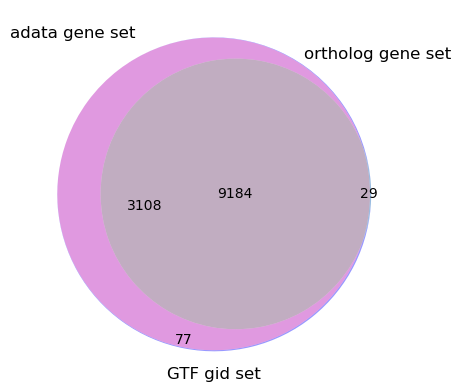

In [28]:
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

v = venn3([Amel_set, Amel_121_set, Amel_gid_set], set_labels=("adata gene set", "ortholog gene set", "GTF gid set"))
plt.show()

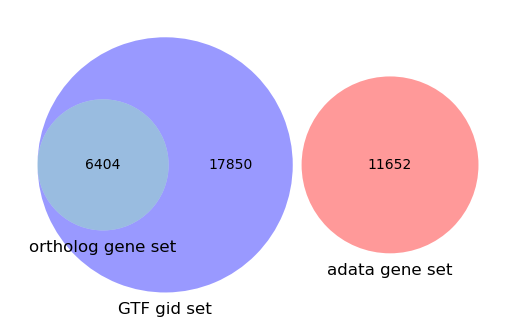

In [15]:
v = venn3([Dmel_set, Dmel_121_set, Dmel_gid_set], set_labels=("adata gene set", "ortholog gene set", "GTF gid set"))
plt.show()

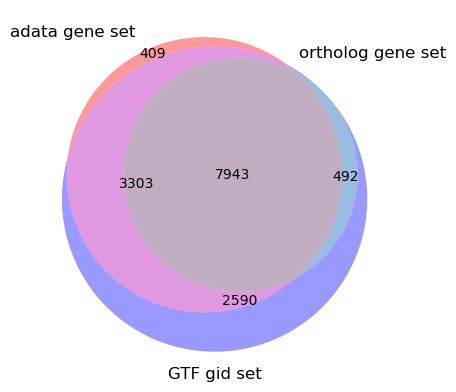

In [16]:
v = venn3([Hsal_set, Hsal_121_set, Hsal_gid_set], set_labels=("adata gene set", "ortholog gene set", "GTF gid set"))
plt.show()

In [18]:
Hsal_set - Hsal_gid_set

{'Anamorsin',
 'Centrin-1',
 'Fut8',
 'G10031',
 'G10062',
 'G10089',
 'G10171',
 'G10292',
 'G10361',
 'G10365',
 'G10409',
 'G10460',
 'G10464',
 'G10543',
 'G10544',
 'G10575',
 'G10737',
 'G1076',
 'G10760',
 'G10761',
 'G1081',
 'G10949',
 'G10993',
 'G11039',
 'G11155',
 'G11353',
 'G1139',
 'G11390',
 'G1152',
 'G11570',
 'G11645',
 'G11723',
 'G1192',
 'G11949',
 'G11963',
 'G120',
 'G12043',
 'G1205',
 'G12077',
 'G12104',
 'G12128',
 'G12129',
 'G12152',
 'G12261',
 'G1230',
 'G12305',
 'G12308',
 'G12345',
 'G12476',
 'G12485',
 'G12486',
 'G12514',
 'G12554',
 'G12556',
 'G12582',
 'G12599',
 'G1260',
 'G1270',
 'G12719',
 'G12788',
 'G12855',
 'G12860',
 'G12876',
 'G12949',
 'G13097',
 'G13138',
 'G13139',
 'G13434',
 'G13435',
 'G1353',
 'G13580',
 'G13662',
 'G13693',
 'G13735',
 'G13736',
 'G13738',
 'G13743',
 'G13744',
 'G13753',
 'G13775',
 'G13803',
 'G13838',
 'G1387',
 'G13901',
 'G13902',
 'G13928',
 'G14031',
 'G14042',
 'G14172',
 'G14189',
 'G14267',
 'G14296

*Apis mellifera*

{'GeneID_408270',
 'GeneID_409148',
 'GeneID_410082',
 'GeneID_807690',
 'GeneID_807691',
 'GeneID_807692',
 'GeneID_807693',
 'GeneID_807695',
 'GeneID_807696',
 'GeneID_807700',
 'LOC100576088',
 'LOC100576186',
 'LOC100576422',
 'LOC100576544',
 'LOC100576610',
 'LOC100576646',
 'LOC100576828',
 'LOC100576960',
 'LOC100576967',
 'LOC100577026',
 'LOC100577053',
 'LOC100577081',
 'LOC100577145',
 'LOC100577533',
 'LOC100577575',
 'LOC100577594',
 'LOC100577673',
 'LOC100577702',
 'LOC100577816',
 'LOC100577856',
 'LOC100577992',
 'LOC100578002',
 'LOC100578109',
 'LOC100578551',
 'LOC100578560',
 'LOC100578624',
 'LOC100578653',
 'LOC100578661',
 'LOC100578735',
 'LOC100579038',
 'LOC100579052',
 'LOC102653753',
 'LOC102654090',
 'LOC102654169',
 'LOC102654216',
 'LOC102654365',
 'LOC102654465',
 'LOC102654681',
 'LOC102654682',
 'LOC102654737',
 'LOC102654768',
 'LOC102654906',
 'LOC102654955',
 'LOC102655050',
 'LOC102655127',
 'LOC102655141',
 'LOC102655391',
 'LOC102655673',
 'LO